# EMQA_L3_term_structure

**Term structure of GARCH(1,1)-t volatility forecasts**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_term_structure/EMQA_L3_term_structure.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

## Term structure of the volatility forecast

$\hat\sigma^2_{T+h\mid T}=\bar\sigma^2+(\alpha+\beta)^{h-1}(\hat\sigma^2_{T+1}-\bar\sigma^2)$, $\bar\sigma^2=\omega/(1-\alpha-\beta)$. For returns without autocorrelation (oil), the variance over $h$ days is $\sum_{k=1}^{h}\hat\sigma^2_{T+k\mid T}$, not $h\hat\sigma^2_{T+1}$; 90% band $=\pm1.645\sqrt{\cdot}$.

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# daily changes on the full calendar: percent (log) and EUR/MWh
r = 100 * np.log(P.where(P > 0)).diff()      # r_t = 100 ln(P_t / P_{t-1}); missing if a price is <= 0
u = P.diff()                                  # Delta P_t = P_t - P_{t-1}, EUR/MWh

In [5]:
import statsmodels.api as sm


def mean_design(y, lags=7):
    # constant + AR(1..7) + six day-of-week dummies (Monday = base)
    X = pd.DataFrame({f'L{k}': y.shift(k) for k in range(1, lags + 1)}, index=y.index)
    for j in range(1, 7):
        X[f'D{j}'] = (y.index.dayofweek == j).astype(float)
    X.insert(0, 'const', 1.0)
    return X


def mean_fit(y, lags=7):
    # OLS mean equation; returns (residuals = shocks, fitted model)
    X = mean_design(y, lags)
    df = pd.concat([y.rename('y'), X], axis=1).dropna()
    m = sm.OLS(df['y'], df.drop(columns='y')).fit()
    return m.resid, m


E_PCT, M_PCT = mean_fit(r)       # shocks epsilon_t, percent
E_EUR, M_EUR = mean_fit(u)       # shocks u_t, EUR/MWh
print('shocks:', E_PCT.index[0].date(), 'to', E_PCT.index[-1].date(), '|', len(E_PCT), 'days')

shocks: 2019-01-09 to 2026-10-31 | 2853 days


In [6]:
try:
    import arch
except ImportError:          # Google Colab: install the arch package once
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'arch'])
from arch import arch_model


def fit(e, vol='GARCH', o=0, dist='t'):
    # zero-mean GARCH(1,1) (o=0) or GJR-GARCH(1,1,1) (o=1), Student-t shocks by default
    return arch_model(np.asarray(e, float), mean='Zero', vol=vol, p=1, o=o, q=1, dist=dist,
                      rescale=False).fit(disp='off', show_warning=False)

In [7]:
def mkt_returns(px, drop_roll=False, vol=None):
    # 100 x log returns on trading days; drop_roll removes the first trading day of each month (futures roll);
    # vol: keep only days with a positive traded volume
    px = px.dropna()
    if vol is not None:
        px = px[vol.reindex(px.index).fillna(0) > 0]
    r_ = 100 * np.log(px).diff().dropna()
    if drop_roll:
        first = r_.index.to_series().groupby(r_.index.to_period('M')).transform('min') == r_.index
        r_ = r_[~first]
    return r_


FU = pd.read_csv(DATA + 'fuels_daily.csv', usecols=['date', 'brent_usd_bbl'], parse_dates=['date']).set_index('date')
BRENT = mkt_returns(FU['brent_usd_bbl'].loc[str(START - pd.Timedelta(days=10)):str(END)], drop_roll=True).loc[START:END]
print('Brent BZ=F returns:', BRENT.index[0].date(), 'to', BRENT.index[-1].date(), '|', len(BRENT), 'trading days (roll days dropped)')

Brent BZ=F returns: 2019-01-03 to 2026-10-30 | 1878 trading days (roll days dropped)


### Numbers on the slide

In [8]:
from scipy import stats
z95 = stats.norm.ppf(0.95)
res = fit(E_EUR)
f = res.forecast(horizon=60, reindex=False).variance.values[-1]
p = res.params
lr = p['omega'] / (1 - p['alpha[1]'] - p['beta[1]'])
slide('Romania: sigma forecast for the next day, EUR/MWh', 'ts.eur.s1', np.sqrt(f[0]), 1)
slide('Romania: long-run sigma, EUR/MWh', 'ts.eur.lr', np.sqrt(lr), 1)
slide('Romania: one-day 90% limit, +/- EUR/MWh', 'ts.eur.lim1', z95 * np.sqrt(f[0]), 0)

# Brent: day of the highest 2026 conditional volatility (full-sample model), then forecasts with data up to that day only
cvb = pd.Series(fit(BRENT - BRENT.mean()).conditional_volatility, index=BRENT.index) * np.sqrt(252)
BPEAK = cvb.loc[str(END.year)].idxmax()
TSB = {}
for tag, t_end in [('peak', BPEAK), ('end', BRENT.index[-1])]:
    xb = BRENT.loc[:t_end]
    gb = fit(xb - xb.mean())
    fb = gb.forecast(horizon=60, reindex=False).variance.values[-1]
    lrb = gb.params['omega'] / (1 - gb.params['alpha[1]'] - gb.params['beta[1]'])
    TSB[tag] = (fb, lrb)
    slide(f'Brent ({tag}): forecast day', f'ts.brent.{tag}.date', str(t_end.date()))
    slide(f'  sigma next day, % a year', f'ts.brent.{tag}.s1_ann', np.sqrt(fb[0] * 252), 0)
    slide(f'  long-run sigma, % a year', f'ts.brent.{tag}.lr_ann', np.sqrt(lrb * 252), 0)
    slide(f'  20-day 90% band, GARCH, +/- %', f'ts.brent.{tag}.band20', z95 * np.sqrt(fb[:20].sum()), 1)
    slide(f'  20-day 90% band, sigma x sqrt(20), +/- %', f'ts.brent.{tag}.band20_sqrt', z95 * np.sqrt(20 * fb[0]), 1)
    slide(f'  sigma x sqrt(20) too wide by, %', f'ts.brent.{tag}.over', 100 * (np.sqrt(20 * fb[0]) / np.sqrt(fb[:20].sum()) - 1), 0)

Romania: sigma forecast for the next day, EUR/MWh          26.0   [ts.eur.s1]
Romania: long-run sigma, EUR/MWh                           27.6   [ts.eur.lr]
Romania: one-day 90% limit, +/- EUR/MWh                    43.0   [ts.eur.lim1]
Brent (peak): forecast day                                 2026-04-09   [ts.brent.peak.date]
  sigma next day, % a year                                 93.0   [ts.brent.peak.s1_ann]
  long-run sigma, % a year                                 39.0   [ts.brent.peak.lr_ann]
  20-day 90% band, GARCH, +/- %                            38.5   [ts.brent.peak.band20]
  20-day 90% band, sigma x sqrt(20), +/- %                 43.1   [ts.brent.peak.band20_sqrt]
  sigma x sqrt(20) too wide by, %                          12.0   [ts.brent.peak.over]
Brent (end): forecast day                                  2026-10-30   [ts.brent.end.date]
  sigma next day, % a year                                 32.0   [ts.brent.end.s1_ann]
  long-run sigma, % a year                 

### Chart

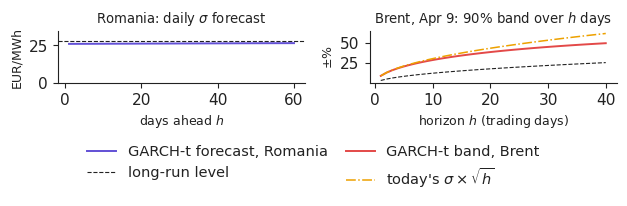

In [9]:
MON = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.1))
h = np.arange(1, 61)
axs[0].plot(h, np.sqrt(f), color=C_EUR, lw=1.4, label='GARCH-t forecast, Romania')
axs[0].axhline(np.sqrt(lr), color='#222222', lw=0.8, ls='--', label='long-run level')
axs[0].set_xlabel('days ahead $h$', fontsize=9)
axs[0].set_ylabel('EUR/MWh', fontsize=9)
axs[0].set_ylim(0, 1.25 * np.sqrt(lr))
axs[0].set_title(r'Romania: daily $\sigma$ forecast', fontsize=9.5)
hb = np.arange(1, 41)
fb, lrb = TSB['peak']
axs[1].plot(hb, z95 * np.sqrt(np.cumsum(fb[:40])), color=PAL['c8'], lw=1.4, label='GARCH-t band, Brent')
axs[1].plot(hb, z95 * np.sqrt(hb * fb[0]), color=PAL['BG'], lw=1.1, ls='-.', label=r"today's $\sigma\times\sqrt{h}$")
axs[1].plot(hb, z95 * np.sqrt(hb * lrb), color='#222222', lw=0.8, ls='--')
axs[1].set_xlabel('horizon $h$ (trading days)', fontsize=9)
axs[1].set_ylabel(r'$\pm$%', fontsize=9)
axs[1].set_title(f'Brent, {MON[BPEAK.month - 1]} {BPEAK.day}: 90% band over $h$ days', fontsize=9.5)
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.27, 1, 1))
plt.savefig('term_structure.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()